In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Understand the dataset

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nChurn Distribution:")
print(df['Churn'].value_counts())


Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [ ]:
# Clean the dataset

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

print("Missing TotalCharges after conversion:",
      df['TotalCharges'].isnull().sum())

# Remove duplicate records if any
df = df.drop_duplicates().copy()

# Remove rows where TotalCharges is missing
df = df.dropna(subset=['TotalCharges']).copy()

print("\nCleaned Dataset Shape:", df.shape)
print("Remaining Missing Values:", df.isnull().sum().sum())

display(df.head())


Missing TotalCharges after conversion: 11

Cleaned Dataset Shape: (7032, 21)
Remaining Missing Values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Total Customers: 7032
Customers Who Churned: 1869
Customers Retained: 5163
Churn Rate: 26.58%
Retention Rate: 73.42%


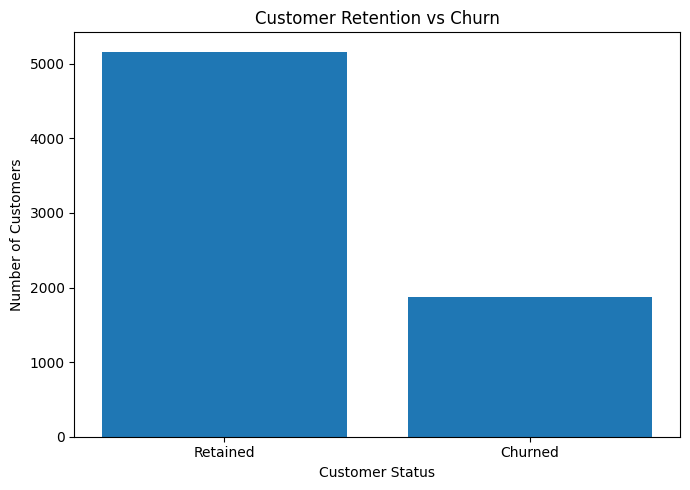

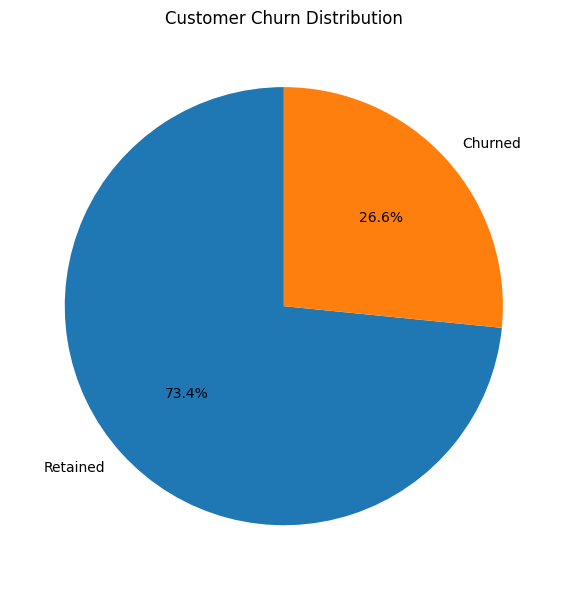

In [ ]:
# Overall Customer Churn Analysis

churn_counts = df['Churn'].value_counts()

total_customers = len(df)
churned_customers = (df['Churn'] == 'Yes').sum()
retained_customers = (df['Churn'] == 'No').sum()

churn_rate = (churned_customers / total_customers) * 100
retention_rate = (retained_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Customers Who Churned:", churned_customers)
print("Customers Retained:", retained_customers)
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")

# Visualize customer status
plt.figure(figsize=(7, 5))
plt.bar(
    ['Retained', 'Churned'],
    [retained_customers, churned_customers]
)

plt.title('Customer Retention vs Churn')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

# Show the percentage distribution
plt.figure(figsize=(6, 6))
plt.pie(
    [retained_customers, churned_customers],
    labels=['Retained', 'Churned'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Churn Distribution')
plt.tight_layout()
plt.show()


Overall Customer Tenure Statistics


,tenure
count,7032.00
mean,32.42
std,24.55
min,1.00
25%,9.00
50%,29.00
75%,55.00
max,72.00



Tenure Comparison: Churned vs Retained


,count,mean,median,min,max
Churn,,,,,
No,5163,37.65,38.0,1,72
Yes,1869,17.98,10.0,1,72


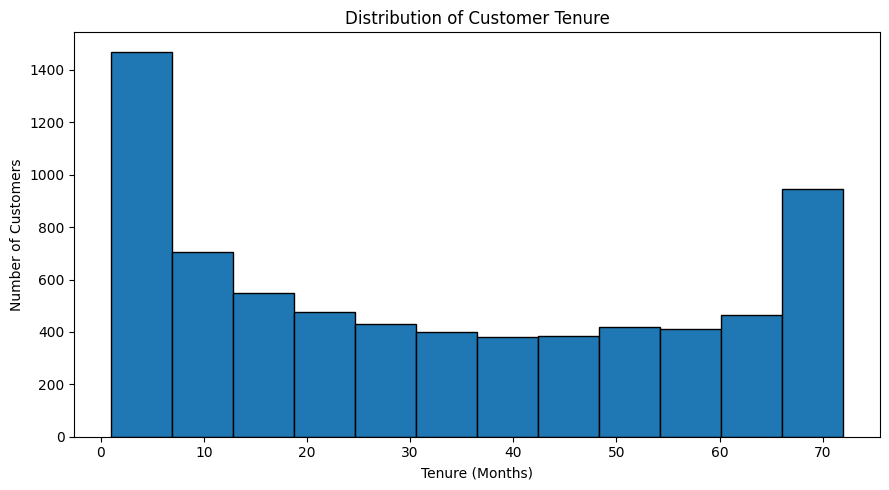

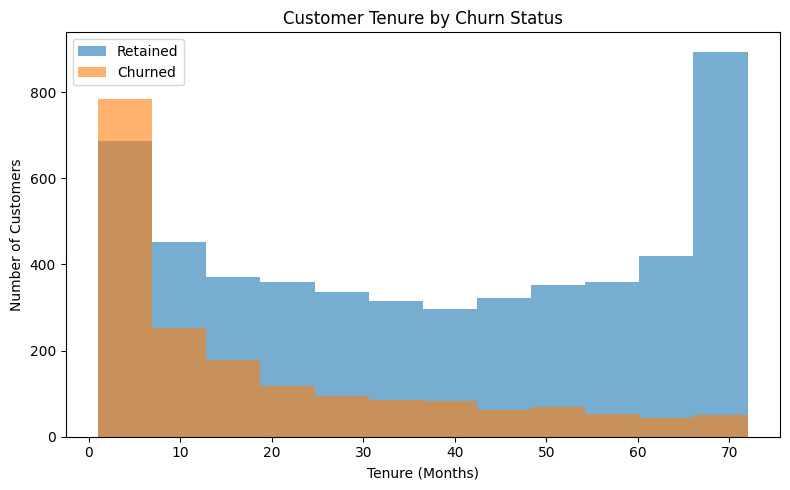

In [ ]:
# Customer Tenure and Lifetime Analysis

print("Overall Customer Tenure Statistics")
display(df['tenure'].describe().to_frame().round(2))

# Compare tenure of churned and retained customers
tenure_analysis = df.groupby('Churn')['tenure'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)

print("\nTenure Comparison: Churned vs Retained")
display(tenure_analysis)

# Distribution of customer tenure
plt.figure(figsize=(9, 5))

plt.hist(df['tenure'], bins=12, edgecolor='black')

plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

# Compare tenure between churn groups
plt.figure(figsize=(8, 5))

for status in ['No', 'Yes']:
    plt.hist(
        df.loc[df['Churn'] == status, 'tenure'],
        bins=12,
        alpha=0.6,
        label='Retained' if status == 'No' else 'Churned'
    )

plt.title('Customer Tenure by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.legend()
plt.tight_layout()
plt.show()


Churn by Internet Service


,InternetService,Total_Customers,Churned_Customers,Churn_Rate_%
1,Fiber optic,3096,1297,41.89
0,DSL,2416,459,19.00
2,No,1520,113,7.43


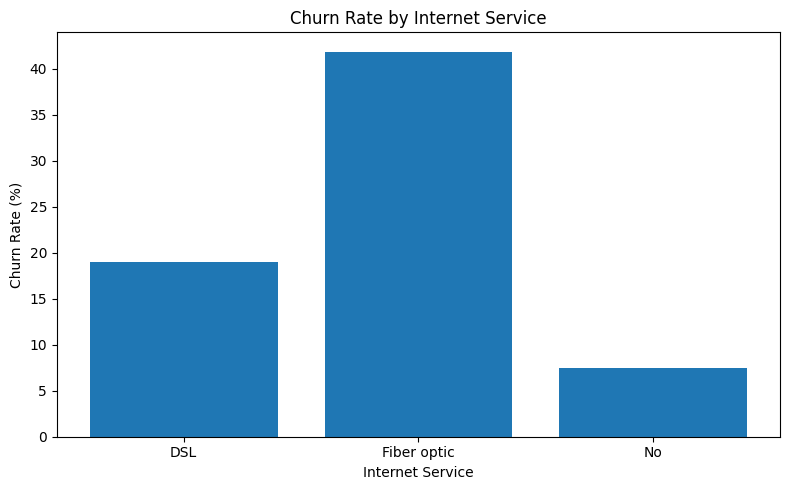

In [ ]:
# Internet Service Analysis

internet_analysis = df.groupby('InternetService').agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
).reset_index()

internet_analysis['Churn_Rate_%'] = (
    internet_analysis['Churned_Customers'] /
    internet_analysis['Total_Customers'] * 100
).round(2)

print("Churn by Internet Service")
display(internet_analysis.sort_values('Churn_Rate_%', ascending=False))

# Visualization

plt.figure(figsize=(8, 5))
plt.bar(
    internet_analysis['InternetService'],
    internet_analysis['Churn_Rate_%']
)
plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()


Churn by Payment Method


,PaymentMethod,Total_Customers,Churned_Customers,Churn_Rate_%
2,Electronic check,2365,1071,45.29
3,Mailed check,1604,308,19.20
0,Bank transfer (automatic),1542,258,16.73
1,Credit card (automatic),1521,232,15.25


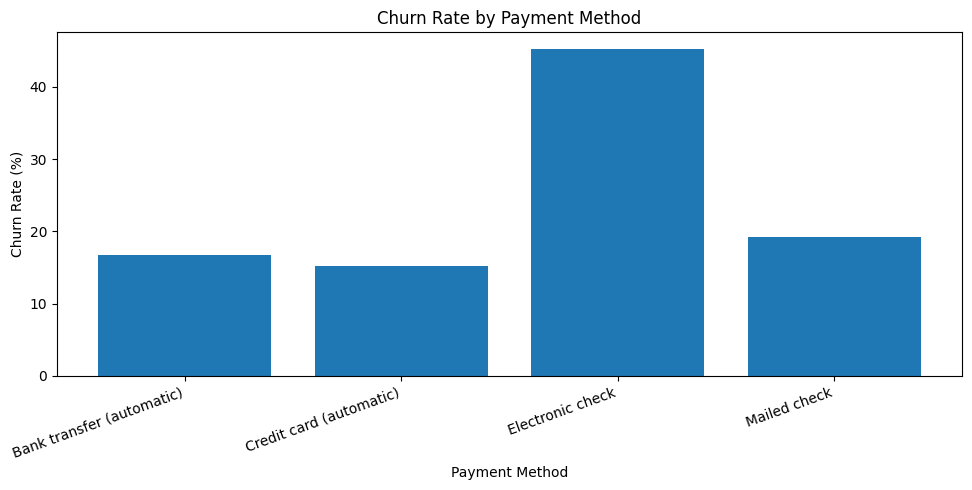

In [ ]:
# Payment Method Analysis

payment_analysis = df.groupby('PaymentMethod').agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
).reset_index()

payment_analysis['Churn_Rate_%'] = (
    payment_analysis['Churned_Customers'] /
    payment_analysis['Total_Customers'] * 100
).round(2)

print("Churn by Payment Method")
display(payment_analysis.sort_values('Churn_Rate_%', ascending=False))

# Visualization

plt.figure(figsize=(10, 5))
plt.bar(
    payment_analysis['PaymentMethod'],
    payment_analysis['Churn_Rate_%']
)
plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()


Monthly Charges Statistics


,MonthlyCharges
count,7032.00
mean,64.80
std,30.09
min,18.25
25%,35.59
50%,70.35
75%,89.86
max,118.75


Monthly Charges: Retained vs Churned Customers


,count,mean,median,min,max
Churn,,,,,
No,5163,61.31,64.45,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


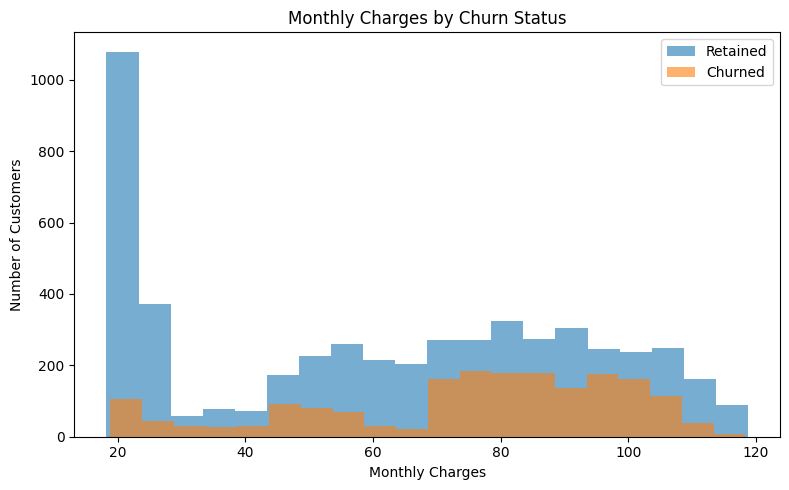

In [ ]:
# Monthly Charges Analysis

print("Monthly Charges Statistics")
display(df['MonthlyCharges'].describe().to_frame().round(2))

# Compare monthly charges of churned and retained customers

charges_analysis = df.groupby('Churn')['MonthlyCharges'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)

print("Monthly Charges: Retained vs Churned Customers")
display(charges_analysis)

# Visualization

plt.figure(figsize=(8, 5))

for status in ['No', 'Yes']:
    plt.hist(
        df.loc[df['Churn'] == status, 'MonthlyCharges'],
        bins=20,
        alpha=0.6,
        label='Retained' if status == 'No' else 'Churned'
    )

plt.title('Monthly Charges by Churn Status')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')
plt.legend()
plt.tight_layout()
plt.show()


Churn Rate by Customer Tenure Group


,TenureGroup,Total_Customers,Churned_Customers,Churn_Rate_%
0,0-12 Months,2175,1037,47.68
1,13-24 Months,1024,294,28.71
2,25-48 Months,1594,325,20.39
3,49-72 Months,2239,213,9.51


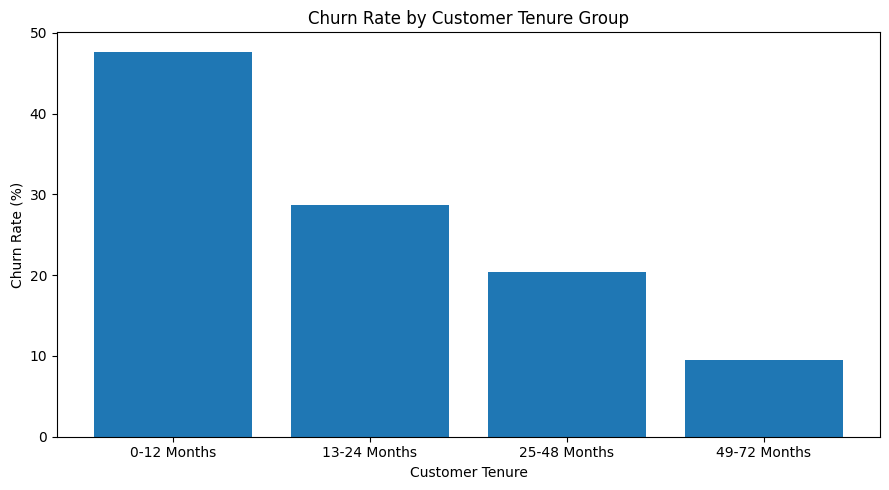

In [ ]:
# Create Customer Tenure Groups

df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-12 Months', '13-24 Months',
            '25-48 Months', '49-72 Months']
)

# Analyze churn in each group

tenure_group_analysis = df.groupby(
    'TenureGroup', observed=False
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
).reset_index()

tenure_group_analysis['Churn_Rate_%'] = (
    tenure_group_analysis['Churned_Customers'] /
    tenure_group_analysis['Total_Customers'] * 100
).round(2)

print("Churn Rate by Customer Tenure Group")
display(tenure_group_analysis)

# Visualization

plt.figure(figsize=(9, 5))
plt.bar(
    tenure_group_analysis['TenureGroup'].astype(str),
    tenure_group_analysis['Churn_Rate_%']
)
plt.title('Churn Rate by Customer Tenure Group')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()


Churn by Tech Support


,TechSupport,Total_Customers,Churned_Customers,Churn_Rate_%
0,No,3472,1446,41.65
2,Yes,2040,310,15.20
1,No internet service,1520,113,7.43


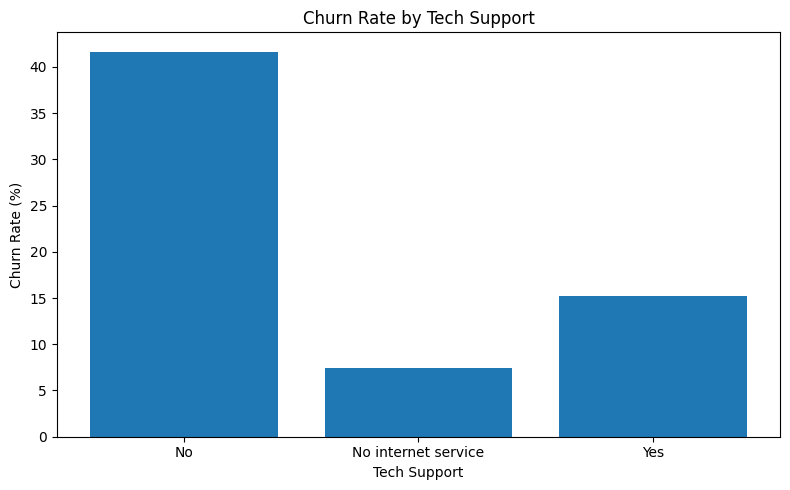

In [ ]:
# Tech Support Analysis

support_analysis = df.groupby('TechSupport').agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
).reset_index()

support_analysis['Churn_Rate_%'] = (
    support_analysis['Churned_Customers'] /
    support_analysis['Total_Customers'] * 100
).round(2)

print("Churn by Tech Support")
display(support_analysis.sort_values('Churn_Rate_%', ascending=False))

# Visualization

plt.figure(figsize=(8, 5))
plt.bar(
    support_analysis['TechSupport'],
    support_analysis['Churn_Rate_%']
)
plt.title('Churn Rate by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()



Churn Analysis by SeniorCitizen


,SeniorCitizen,Total_Customers,Churned_Customers,Churn_Rate_%
0,0,5890,1393,23.65
1,1,1142,476,41.68


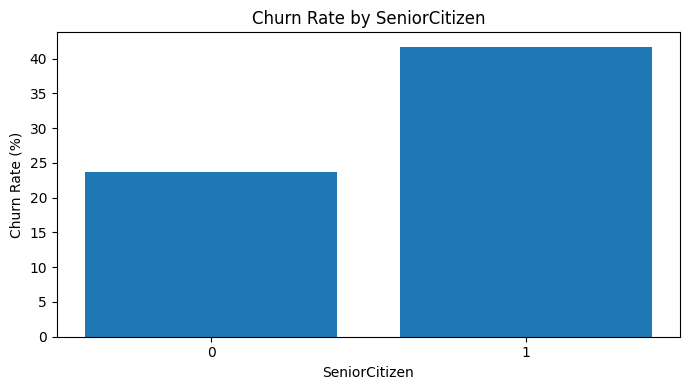


Churn Analysis by Partner


,Partner,Total_Customers,Churned_Customers,Churn_Rate_%
0,No,3639,1200,32.98
1,Yes,3393,669,19.72


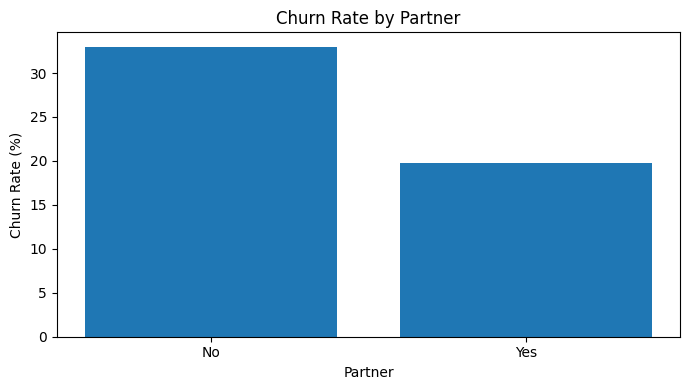

In [ ]:
# Customer Characteristics Analysis

for column in ['SeniorCitizen', 'Partner']:

    analysis = df.groupby(column).agg(
        Total_Customers=('customerID', 'count'),
        Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
    ).reset_index()

    analysis['Churn_Rate_%'] = (
        analysis['Churned_Customers'] /
        analysis['Total_Customers'] * 100
    ).round(2)

    print(f"\nChurn Analysis by {column}")
    display(analysis)

    # Visualization
    plt.figure(figsize=(7, 4))
    plt.bar(
        analysis[column].astype(str),
        analysis['Churn_Rate_%']
    )
    plt.title(f'Churn Rate by {column}')
    plt.xlabel(column)
    plt.ylabel('Churn Rate (%)')
    plt.tight_layout()
    plt.show()


In [ ]:
# Business Insights Summary

columns_to_analyze = [
    'Contract',
    'InternetService',
    'PaymentMethod',
    'TechSupport',
    'TenureGroup',
    'SeniorCitizen',
    'Partner'
]

for column in columns_to_analyze:
    summary = df.groupby(column, observed=False).agg(
        Total_Customers=('Churn', 'count'),
        Churned_Customers=(
            'Churn',
            lambda x: (x == 'Yes').sum()
        )
    ).reset_index()

    summary['Churn_Rate_%'] = (
        summary['Churned_Customers'] /
        summary['Total_Customers'] * 100
    ).round(2)

    print(f"\n--- {column} ---")
    display(summary.sort_values('Churn_Rate_%', ascending=False))

# Compare average monthly charges

print("\nMonthly Charges: Retained vs Churned")

display(
    df.groupby('Churn')['MonthlyCharges']
    .mean()
    .round(2)
    .to_frame(name='Average_Monthly_Charges')
)



--- Contract ---


,Contract,Total_Customers,Churned_Customers,Churn_Rate_%
0,Month-to-month,3875,1655,42.71
1,One year,1472,166,11.28
2,Two year,1685,48,2.85



--- InternetService ---


,InternetService,Total_Customers,Churned_Customers,Churn_Rate_%
1,Fiber optic,3096,1297,41.89
0,DSL,2416,459,19.00
2,No,1520,113,7.43



--- PaymentMethod ---


...

,SeniorCitizen,Total_Customers,Churned_Customers,Churn_Rate_%
1,1,1142,476,41.68
0,0,5890,1393,23.65



--- Partner ---


,Partner,Total_Customers,Churned_Customers,Churn_Rate_%
0,No,3639,1200,32.98
1,Yes,3393,669,19.72



Monthly Charges: Retained vs Churned


,Average_Monthly_Charges
Churn,
No,61.31
Yes,74.44


CUSTOMER RETENTION & CHURN DASHBOARD
Total Customers: 7032
Churned Customers: 1869
Retained Customers: 5163
Churn Rate: 26.58%
Retention Rate: 73.42%


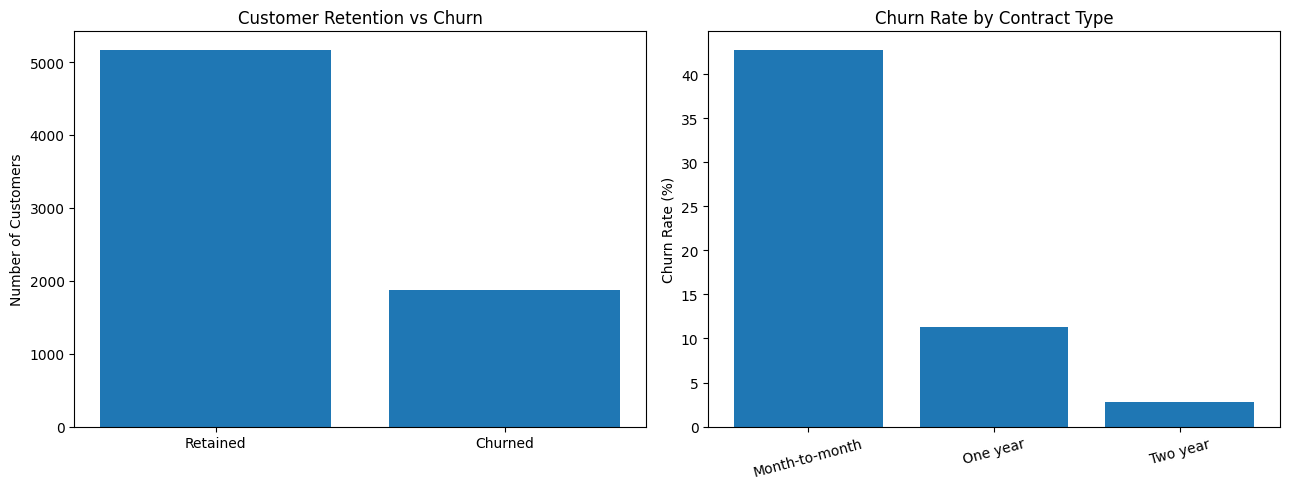

In [ ]:
# Customer Churn Dashboard

total_customers = len(df)
churned = (df['Churn'] == 'Yes').sum()
retained = (df['Churn'] == 'No').sum()
churn_rate = churned / total_customers * 100
retention_rate = retained / total_customers * 100

print("=" * 40)
print("CUSTOMER RETENTION & CHURN DASHBOARD")
print("=" * 40)
print("Total Customers:", total_customers)
print("Churned Customers:", churned)
print("Retained Customers:", retained)
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")

# Create dashboard graphs

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graph 1: Churn Distribution
axes[0].bar(
    ['Retained', 'Churned'],
    [retained, churned]
)
axes[0].set_title('Customer Retention vs Churn')
axes[0].set_ylabel('Number of Customers')

# Graph 2: Churn by Contract
contract_rates = df.groupby('Contract').apply(
    lambda group: (group['Churn'] == 'Yes').mean() * 100,
    include_groups=False
)

axes[1].bar(
    contract_rates.index,
    contract_rates.values
)
axes[1].set_title('Churn Rate by Contract Type')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()


In [ ]:
#Final Business Summary

total_customers = len(df)
churned = (df['Churn'] == 'Yes').sum()
retained = (df['Churn'] == 'No').sum()

print("FINAL BUSINESS SUMMARY")
print("-" * 35)
print(f"Total Customers: {total_customers}")
print(f"Churned Customers: {churned}")
print(f"Retained Customers: {retained}")
print(f"Churn Rate: {churned / total_customers * 100:.2f}%")
print(f"Retention Rate: {retained / total_customers * 100:.2f}%")

# Contract with highest churn rate
contract_rates = df.groupby('Contract').apply(
    lambda group: (group['Churn'] == 'Yes').mean() * 100
)

print("\nChurn Rate by Contract:")
display(contract_rates.round(2).to_frame('Churn_Rate_%'))

print("\nAverage Monthly Charges:")
display(
    df.groupby('Churn')['MonthlyCharges']
    .mean()
    .round(2)
    .to_frame('Average_Monthly_Charges')
)


FINAL BUSINESS SUMMARY
-----------------------------------
Total Customers: 7032
Churned Customers: 1869
Retained Customers: 5163
Churn Rate: 26.58%
Retention Rate: 73.42%

Churn Rate by Contract:


/tmp/ipykernel_4371/1264855158.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  contract_rates = df.groupby('Contract').apply(


,Churn_Rate_%
Contract,
Month-to-month,42.71
One year,11.28
Two year,2.85



Average Monthly Charges:


,Average_Monthly_Charges
Churn,
No,61.31
Yes,74.44


## Conclusion

This project analyzed customer churn and retention patterns using exploratory data analysis and data visualization. The findings can help identify customers at higher risk of leaving and suggest strategies to improve customer retention and satisfaction.